# Data Cleaning and Preprocessing

**Oasis Infobyte – Data Analytics Internship**

**Level 1 – Task 3**

## Project Objective

The objective of this project is to identify and correct data quality issues using Python.

The project focuses on handling missing values, removing duplicate records, correcting inconsistent formatting, checking data types and identifying potential outliers.

The cleaned dataset will be compared with the original dataset to evaluate the impact of preprocessing and prepare the data for further analysis.

In [74]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [75]:
import pandas as pd
import glob

print("Available CSV files:")
print(glob.glob("/content/*.csv"))

Available CSV files:
['/content/Snitch_Fashion_Sales_Uncleaned.csv', '/content/Snitch_Fashion_Sales_Cleaned.csv']


## Dataset Loading and Initial Inspection

This project uses the Snitch Fashion Sales Uncleaned dataset.

The first stage involves examining the dataset's structure, column names, data types, missing values and duplicate records.

These checks will help identify data quality issues and determine suitable cleaning techniques.

In [76]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(
    "/content/Snitch_Fashion_Sales_Uncleaned.csv"
)

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nFirst 5 Rows:")
display(df.head())

Dataset Shape: (2500, 12)

Column Names:
['Order_ID', 'Customer_Name', 'Product_Category', 'Product_Name', 'Units_Sold', 'Unit_Price', 'Discount_%', 'Sales_Amount', 'Order_Date', 'City', 'Segment', 'Profit']

First 5 Rows:


,Order_ID,Customer_Name,Product_Category,Product_Name,Units_Sold,Unit_Price,Discount_%,Sales_Amount,Order_Date,City,Segment,Profit
0,1000,Brian Thompson,Jeans,Slim Fit Jeans,NaN,842.00,0.60,0.00,2025-02-27,Delhi,B2C,2137.45
1,1001,Shaun Ross,Jeans,Slim Fit Jeans,1.0,NaN,NaN,0.00,2025-07-15,Ahmedabad,NaN,1588.15
2,1002,Sarah Snyder,Jackets,Puffer Coat,1.0,637.82,NaN,0.00,02-01-2025,Mumbai,B2B,-158.03
3,1003,Jay Briggs,Shoes,Loafers,2.0,2962.27,NaN,0.00,18-06-2025,bengaluru,B2B,2296.50
4,1004,Maria Blake,Accessories,Belts,1.0,2881.07,0.27,2103.18,NaN,hyderbad,NaN,63.66


In [77]:
print("Dataset Information:")
df.info()

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Order_ID          2500 non-null   int64  
 1   Customer_Name     2500 non-null   object 
 2   Product_Category  2500 non-null   object 
 3   Product_Name      2500 non-null   object 
 4   Units_Sold        1194 non-null   float64
 5   Unit_Price        1290 non-null   float64
 6   Discount_%        849 non-null    float64
 7   Sales_Amount      2500 non-null   float64
 8   Order_Date        1894 non-null   object 
 9   City              2500 non-null   object 
 10  Segment           1679 non-null   object 
 11  Profit            2500 non-null   float64
dtypes: float64(5), int64(1), object(6)
memory usage: 234.5+ KB


In [78]:
print("Missing Values in Each Column:")
print(df.isnull().sum())

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

Missing Values in Each Column:
Order_ID               0
Customer_Name          0
Product_Category       0
Product_Name           0
Units_Sold          1306
Unit_Price          1210
Discount_%          1651
Sales_Amount           0
Order_Date           606
City                   0
Segment              821
Profit                 0
dtype: int64

Total Missing Values:
5594


In [79]:
print("Duplicate Rows:")
print(df.duplicated().sum())

Duplicate Rows:
0


In [80]:
print("Numerical Statistics:")
display(df.describe())

print("\nCategorical Statistics:")
display(df.describe(include="object"))

Numerical Statistics:


,Order_ID,Units_Sold,Unit_Price,Discount_%,Sales_Amount,Profit
count,2500.000000,1194.000000,1290.000000,849.000000,2500.000000,2500.000000
mean,2193.060000,1.940536,2691.715527,0.646466,126.756252,981.569032
std,748.063846,2.625680,1320.448967,0.380331,1464.944525,1159.159244
min,1000.000000,-2.000000,400.210000,0.000000,-7518.330000,-992.610000
25%,1543.750000,0.000000,1526.195000,0.300000,0.000000,-19.670000
50%,2182.500000,2.000000,2685.985000,0.650000,0.000000,947.885000
75%,2842.250000,4.000000,3824.347500,0.980000,0.000000,1993.515000
max,3499.000000,6.000000,4998.910000,1.300000,29180.680000,2997.110000



Categorical Statistics:


,Customer_Name,Product_Category,Product_Name,Order_Date,City,Segment
count,2500,2500,2500,1894,2500,1679
unique,2458,6,24,1017,9,2
top,Michael Smith,Dresses,Wrap Dress,2025/05/05,Mumbai,B2B
freq,4,443,126,8,443,844


In [81]:
df_original = df.copy()

print("Original dataset preserved successfully!")

Original dataset preserved successfully!


## Handling Missing Values

The dataset contains 2,500 records and 12 columns. Initial inspection identified 5,594 missing cells across five columns: Units_Sold, Unit_Price, Discount_%, Order_Date and Segment.

There are no exact duplicate rows.

Before handling missing values, the missing-data patterns and available relationships between columns will be examined. This will help determine whether values can be recovered, estimated or should remain missing.

The original dataset will be preserved to allow comparison with the cleaned version.

In [82]:
df_clean = df.copy()

print("Working copy created successfully!")
print("Rows:", len(df_clean))

Working copy created successfully!
Rows: 2500


In [83]:
# Check rows with complete sales information
complete_sales = df_clean.dropna(
    subset=["Units_Sold", "Unit_Price", "Discount_%"]
).copy()

print("Rows with complete sales information:",
      len(complete_sales))

display(
    complete_sales[
        ["Units_Sold", "Unit_Price",
         "Discount_%", "Sales_Amount"]
    ].head(10)
)

Rows with complete sales information: 206


,Units_Sold,Unit_Price,Discount_%,Sales_Amount
4,1.0,2881.07,0.27,2103.18
34,0.0,4449.36,0.94,0.00
46,-1.0,2441.92,0.92,-195.35
59,0.0,2927.57,0.19,0.00
69,2.0,2102.02,1.13,-546.53
81,6.0,4798.06,0.81,5469.79
114,6.0,568.61,0.20,2729.33
122,0.0,4745.03,0.40,0.00
127,3.0,4843.44,0.07,13513.20
129,-2.0,2412.36,0.23,-3715.03


In [84]:
print("Discount Statistics:")
print(df_clean["Discount_%"].describe())

print("\nUnique Discount Values:")
print(
    sorted(
        df_clean["Discount_%"].dropna().unique()
    )[:30]
)

Discount Statistics:
count    849.000000
mean       0.646466
std        0.380331
min        0.000000
25%        0.300000
50%        0.650000
75%        0.980000
max        1.300000
Name: Discount_%, dtype: float64

Unique Discount Values:
[np.float64(0.0), np.float64(0.01), np.float64(0.02), np.float64(0.03), np.float64(0.04), np.float64(0.05), np.float64(0.06), np.float64(0.07), np.float64(0.08), np.float64(0.09), np.float64(0.1), np.float64(0.11), np.float64(0.12), np.float64(0.13), np.float64(0.14), np.float64(0.15), np.float64(0.16), np.float64(0.17), np.float64(0.18), np.float64(0.19), np.float64(0.2), np.float64(0.21), np.float64(0.22), np.float64(0.23), np.float64(0.24), np.float64(0.25), np.float64(0.26), np.float64(0.27), np.float64(0.28), np.float64(0.29)]


In [85]:
columns = [
    "Units_Sold",
    "Unit_Price",
    "Discount_%",
    "Order_Date",
    "Segment"
]

missing_patterns = (
    df_clean[columns]
    .isna()
    .value_counts()
    .reset_index(name="Count")
    .sort_values("Count", ascending=False)
)

display(missing_patterns.head(10))

,Units_Sold,Unit_Price,Discount_%,Order_Date,Segment,Count
0,True,False,True,False,False,238
1,False,False,True,False,False,213
2,True,True,True,False,False,213
3,False,True,True,False,False,189
4,True,False,True,False,True,122
5,False,False,False,False,False,113
6,True,False,False,False,False,107
7,True,True,True,False,True,102
8,True,True,False,False,False,100
9,False,True,False,False,False,97


In [86]:
print("Sample Order Dates:")
print(df_clean["Order_Date"].dropna().head(15).tolist())

print("\nSegment Values:")
print(df_clean["Segment"].value_counts(dropna=False))

print("\nProduct Categories:")
print(df_clean["Product_Category"].value_counts())

print("\nCity Values:")
print(df_clean["City"].value_counts().head(20))

Sample Order Dates:
['2025-02-27', '2025-07-15', '02-01-2025', '18-06-2025', '2023-12-05', '2024-04-02', '2025-07-20', '27-05-2025', '2024/08/22', '21-09-2024', '26-10-2024', '2024-04-13', '2024/10/22', '19-03-2025', '2024-05-05']

Segment Values:
Segment
B2B    844
B2C    835
NaN    821
Name: count, dtype: int64

Product Categories:
Product_Category
Dresses        443
T-Shirts       415
Accessories    411
Jackets        411
Jeans          410
Shoes          410
Name: count, dtype: int64

City Values:
City
Mumbai       443
Ahmedabad    431
Delhi        409
Pune         383
Bangalore    207
bengaluru    191
Hyd          153
hyderbad     145
Hyderabad    138
Name: count, dtype: int64


##Data Cleaning and Missing Value Treatment

The dataset contains missing values in Units_Sold, Unit_Price, Discount_%, Order_Date and Segment.

Missing numerical values will be examined and treated using appropriate methods. Missing categorical values will be labelled where their original values cannot be recovered.

Missing dates will remain unavailable rather than being replaced with invented transaction dates.

The cleaning process will preserve the original dataset and document any imputed or unrecoverable values.

In [87]:
df_clean = df.copy()

print("Original Records:", len(df))
print("Working Records:", len(df_clean))

Original Records: 2500
Working Records: 2500


In [88]:
text_columns = [
    "Customer_Name",
    "Product_Category",
    "Product_Name",
    "City",
    "Segment"
]

for col in text_columns:
    df_clean[col] = (
        df_clean[col]
        .astype("string")
        .str.strip()
        .str.replace(r"\s+", " ", regex=True)
    )

print("Text formatting standardised.")

for col in ["Product_Category", "City", "Segment"]:
    print(f"\n{col}:")
    print(df_clean[col].value_counts(dropna=False).head(20))

Text formatting standardised.

Product_Category:
Product_Category
Dresses        443
T-Shirts       415
Accessories    411
Jackets        411
Jeans          410
Shoes          410
Name: count, dtype: Int64

City:
City
Mumbai       443
Ahmedabad    431
Delhi        409
Pune         383
Bangalore    207
bengaluru    191
Hyd          153
hyderbad     145
Hyderabad    138
Name: count, dtype: Int64

Segment:
Segment
B2B     844
B2C     835
<NA>    821
Name: count, dtype: Int64


In [89]:
df_clean["City"] = (
    df_clean["City"]
    .replace({
        "bengaluru": "Bangalore",
        "Hyd": "Hyderabad",
        "hyderbad": "Hyderabad"
    })
)

print(df_clean["City"].value_counts())

City
Mumbai       443
Hyderabad    436
Ahmedabad    431
Delhi        409
Bangalore    398
Pune         383
Name: count, dtype: Int64


In [90]:
#Handle missing Segment values
df_clean["Segment"] = (
    df_clean["Segment"]
    .fillna("Unknown")
)

print("Remaining Missing Segment Values:",
      df_clean["Segment"].isna().sum())

Remaining Missing Segment Values: 0


In [91]:
#Handle missing Numeric values
numeric_columns = ["Units_Sold", "Unit_Price"]

for col in numeric_columns:

    df_clean[col + "_Was_Missing"] = (
        df_clean[col].isna()
    )

    median_value = df_clean[col].median()

    df_clean[col] = (
        df_clean[col].fillna(median_value)
    )

    print(f"{col} median used: {median_value}")

Units_Sold median used: 2.0
Unit_Price median used: 2685.985


In [92]:
df_clean["Order_Date"] = pd.to_datetime(
    df_original["Order_Date"],
    format="mixed",
    dayfirst=True,
    errors="coerce"
)

print("Missing Dates After Conversion:",
      df_clean["Order_Date"].isna().sum())

print("Sample Converted Dates:")
print(df_clean["Order_Date"].dropna().head(10))

Missing Dates After Conversion: 606
Sample Converted Dates:
0    2025-02-27
1    2025-07-15
2    2025-01-02
3    2025-06-18
5    2023-12-05
6    2024-04-02
9    2025-07-20
11   2025-05-27
12   2024-08-22
14   2024-09-21
Name: Order_Date, dtype: datetime64[ns]


In [93]:
print("Missing Values After Initial Cleaning:")
print(df_clean.isna().sum())

print("\nDataset Shape:")
print(df_clean.shape)

print("\nFirst Five Rows:")
display(df_clean.head())

Missing Values After Initial Cleaning:
Order_ID                     0
Customer_Name                0
Product_Category             0
Product_Name                 0
Units_Sold                   0
Unit_Price                   0
Discount_%                1651
Sales_Amount                 0
Order_Date                 606
City                         0
Segment                      0
Profit                       0
Units_Sold_Was_Missing       0
Unit_Price_Was_Missing       0
dtype: int64

Dataset Shape:
(2500, 14)

First Five Rows:


,Order_ID,Customer_Name,Product_Category,Product_Name,Units_Sold,Unit_Price,Discount_%,Sales_Amount,Order_Date,City,Segment,Profit,Units_Sold_Was_Missing,Unit_Price_Was_Missing
0,1000,Brian Thompson,Jeans,Slim Fit Jeans,2.0,842.000,0.60,0.00,2025-02-27,Delhi,B2C,2137.45,True,False
1,1001,Shaun Ross,Jeans,Slim Fit Jeans,1.0,2685.985,NaN,0.00,2025-07-15,Ahmedabad,Unknown,1588.15,False,True
2,1002,Sarah Snyder,Jackets,Puffer Coat,1.0,637.820,NaN,0.00,2025-01-02,Mumbai,B2B,-158.03,False,False
3,1003,Jay Briggs,Shoes,Loafers,2.0,2962.270,NaN,0.00,2025-06-18,Bangalore,B2B,2296.50,False,False
4,1004,Maria Blake,Accessories,Belts,1.0,2881.070,0.27,2103.18,NaT,Hyderabad,Unknown,63.66,False,False


In [94]:
#Check for invalid numerical values and outliers
columns = [
    "Units_Sold",
    "Unit_Price",
    "Discount_%",
    "Sales_Amount",
    "Profit"
]

print("Numerical Summary:")
display(df_clean[columns].describe())

print("\nNon-positive Units Sold:",
      (df_clean["Units_Sold"] <= 0).sum())

print("Negative Unit Prices:",
      (df_clean["Unit_Price"] < 0).sum())

print("Negative Sales Amounts:",
      (df_clean["Sales_Amount"] < 0).sum())

print("\nDiscount Values:")
print(sorted(df_clean["Discount_%"].dropna().unique())[:30])

Numerical Summary:


,Units_Sold,Unit_Price,Discount_%,Sales_Amount,Profit
count,2500.000000,2500.000000,849.000000,2500.000000,2500.000000
mean,1.971600,2688.941952,0.646466,126.756252,981.569032
std,1.814417,948.346253,0.380331,1464.944525,1159.159244
min,-2.000000,400.210000,0.000000,-7518.330000,-992.610000
25%,2.000000,2627.007500,0.300000,0.000000,-19.670000
50%,2.000000,2685.985000,0.650000,0.000000,947.885000
75%,2.000000,2739.635000,0.980000,0.000000,1993.515000
max,6.000000,4998.910000,1.300000,29180.680000,2997.110000



Non-positive Units Sold: 412
Negative Unit Prices: 0
Negative Sales Amounts: 70

Discount Values:
[np.float64(0.0), np.float64(0.01), np.float64(0.02), np.float64(0.03), np.float64(0.04), np.float64(0.05), np.float64(0.06), np.float64(0.07), np.float64(0.08), np.float64(0.09), np.float64(0.1), np.float64(0.11), np.float64(0.12), np.float64(0.13), np.float64(0.14), np.float64(0.15), np.float64(0.16), np.float64(0.17), np.float64(0.18), np.float64(0.19), np.float64(0.2), np.float64(0.21), np.float64(0.22), np.float64(0.23), np.float64(0.24), np.float64(0.25), np.float64(0.26), np.float64(0.27), np.float64(0.28), np.float64(0.29)]


## Discount Validation and Outlier Detection

This stage examines the Discount_% column and identifies potential outliers in numerical variables.

Discount values are checked for their scale and valid range before missing values are handled. Potential outliers are identified using the Interquartile Range (IQR) method.

Outliers are not automatically removed because unusually large sales or profits may represent genuine business transactions.

In [95]:
print("Discount Statistics:")
display(df_clean["Discount_%"].describe())

print("\nUnique Discount Values:")
print(sorted(df_clean["Discount_%"].dropna().unique()))

print("\nMissing Discounts:")
print(df_clean["Discount_%"].isna().sum())

Discount Statistics:


,Discount_%
count,849.000000
mean,0.646466
std,0.380331
min,0.000000
25%,0.300000
50%,0.650000
75%,0.980000
max,1.300000



Unique Discount Values:
[np.float64(0.0), np.float64(0.01), np.float64(0.02), np.float64(0.03), np.float64(0.04), np.float64(0.05), np.float64(0.06), np.float64(0.07), np.float64(0.08), np.float64(0.09), np.float64(0.1), np.float64(0.11), np.float64(0.12), np.float64(0.13), np.float64(0.14), np.float64(0.15), np.float64(0.16), np.float64(0.17), np.float64(0.18), np.float64(0.19), np.float64(0.2), np.float64(0.21), np.float64(0.22), np.float64(0.23), np.float64(0.24), np.float64(0.25), np.float64(0.26), np.float64(0.27), np.float64(0.28), np.float64(0.29), np.float64(0.3), np.float64(0.31), np.float64(0.32), np.float64(0.33), np.float64(0.34), np.float64(0.35), np.float64(0.36), np.float64(0.37), np.float64(0.38), np.float64(0.39), np.float64(0.4), np.float64(0.41), np.float64(0.42), np.float64(0.43), np.float64(0.44), np.float64(0.45), np.float64(0.46), np.float64(0.47), np.float64(0.48), np.float64(0.49), np.float64(0.5), np.float64(0.51), np.float64(0.52), np.float64(0.53), np.float

In [96]:
print("Discount values greater than 1:",
      (df_original["Discount_%"] > 1).sum())

print("Maximum discount:",
      df_original["Discount_%"].max())

print("Minimum discount:",
      df_original["Discount_%"].min())

print("\nUnique Discount Values:")
print(sorted(df_original["Discount_%"].dropna().unique()))

Discount values greater than 1: 189
Maximum discount: 1.3
Minimum discount: 0.0

Unique Discount Values:
[np.float64(0.0), np.float64(0.01), np.float64(0.02), np.float64(0.03), np.float64(0.04), np.float64(0.05), np.float64(0.06), np.float64(0.07), np.float64(0.08), np.float64(0.09), np.float64(0.1), np.float64(0.11), np.float64(0.12), np.float64(0.13), np.float64(0.14), np.float64(0.15), np.float64(0.16), np.float64(0.17), np.float64(0.18), np.float64(0.19), np.float64(0.2), np.float64(0.21), np.float64(0.22), np.float64(0.23), np.float64(0.24), np.float64(0.25), np.float64(0.26), np.float64(0.27), np.float64(0.28), np.float64(0.29), np.float64(0.3), np.float64(0.31), np.float64(0.32), np.float64(0.33), np.float64(0.34), np.float64(0.35), np.float64(0.36), np.float64(0.37), np.float64(0.38), np.float64(0.39), np.float64(0.4), np.float64(0.41), np.float64(0.42), np.float64(0.43), np.float64(0.44), np.float64(0.45), np.float64(0.46), np.float64(0.47), np.float64(0.48), np.float64(0.49),

In [97]:
# Preserve original discount values
original_discount = df_original["Discount_%"]

# Identify missing discounts
df_clean["Discount_Was_Missing"] = (
    original_discount.isna()
)

# Identify invalid discounts
# Valid fractional discount range: 0 to 1
df_clean["Discount_Was_Invalid"] = (
    original_discount.notna() &
    ~original_discount.between(0, 1)
)

print("Originally Missing Discounts:",
      df_clean["Discount_Was_Missing"].sum())

print("Invalid Discounts:",
      df_clean["Discount_Was_Invalid"].sum())

# Replace invalid values with NaN
df_clean.loc[
    df_clean["Discount_Was_Invalid"],
    "Discount_%"
] = np.nan

# Calculate median from valid discounts
median_discount = df_clean["Discount_%"].median()

# Fill missing and invalid discounts
df_clean["Discount_%"] = (
    df_clean["Discount_%"].fillna(median_discount)
)

print("\nMedian Discount Used:", median_discount)

print("Remaining Missing Discounts:",
      df_clean["Discount_%"].isna().sum())

print("Discount Minimum:",
      df_clean["Discount_%"].min())

print("Discount Maximum:",
      df_clean["Discount_%"].max())

Originally Missing Discounts: 1651
Invalid Discounts: 189

Median Discount Used: 0.51
Remaining Missing Discounts: 0
Discount Minimum: 0.0
Discount Maximum: 1.0


### Discount Data Cleaning

The Discount_% column contained values ranging from 0.00 to 1.30. Assuming the values represent fractional discounts, the valid range is 0.00 to 1.00.

A total of 189 observed discount values exceeded the valid upper limit. These values were flagged as invalid and replaced with missing values.

The missing and invalid discount values were then estimated using the median of the valid observed discounts.

Separate indicator columns were maintained to distinguish originally missing values from invalid values identified during preprocessing.

In [98]:
#Detect outliers using IQR
numeric_cols = [
    "Units_Sold",
    "Unit_Price",
    "Sales_Amount",
    "Profit"
]

outlier_results = []

for col in numeric_cols:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = (
        (df_clean[col] < lower_bound) |
        (df_clean[col] > upper_bound)
    )

    df_clean[col + "_Outlier"] = outliers

    outlier_results.append({
        "Column": col,
        "Lower_Bound": round(lower_bound, 2),
        "Upper_Bound": round(upper_bound, 2),
        "Outlier_Count": int(outliers.sum())
    })

outlier_summary = pd.DataFrame(outlier_results)

display(outlier_summary)

,Column,Lower_Bound,Upper_Bound,Outlier_Count
0,Units_Sold,2.00,2.00,1077
1,Unit_Price,2458.07,2908.58,1157
2,Sales_Amount,0.00,0.00,179
3,Profit,-3039.45,5013.29,0


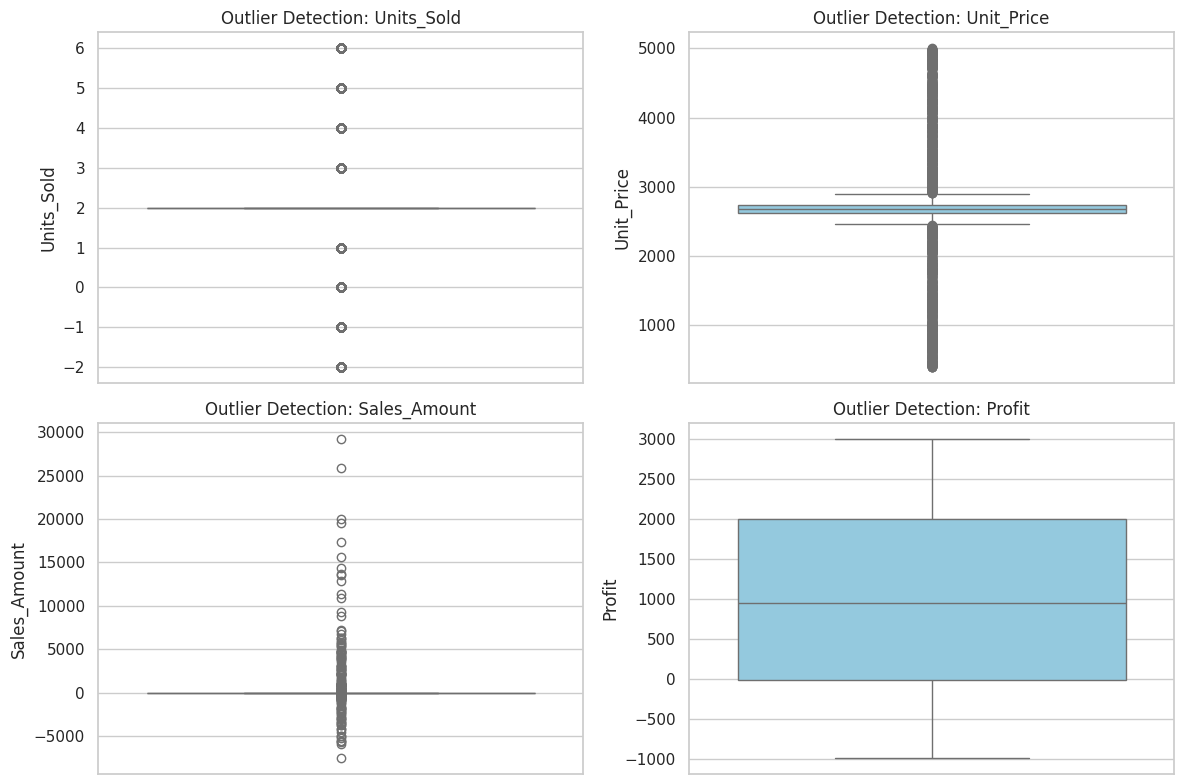

In [99]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, col in zip(axes.flat, numeric_cols):
    sns.boxplot(
        y=df_clean[col],
        ax=ax,
        color="skyblue"
    )

    ax.set_title(f"Outlier Detection: {col}")

plt.tight_layout()
plt.show()

### Outlier Analysis Observations

The Interquartile Range method was applied to Units_Sold, Unit_Price, Sales_Amount and Profit to identify potentially unusual observations.

Box plots were generated to examine the distributions of these variables.

The detected outliers were retained at this stage because the available information does not establish whether they are data-entry errors or genuine business transactions. Removing them without further investigation could distort the sales and profit distributions.

## Before-and-After Data Quality Comparison

This section compares the original Snitch Fashion Sales dataset with the processed dataset.

The comparison examines missing values, duplicate records, data types and the number of records retained after cleaning.

The purpose is to measure the impact of preprocessing and identify any data quality issues that remain unresolved.

In [100]:
# Compare missing values in original columns only
original_columns = df_original.columns.tolist()

before_missing = df_original.isnull().sum()
after_missing = df_clean[original_columns].isnull().sum()

missing_comparison = pd.DataFrame({
    "Before Cleaning": before_missing,
    "After Cleaning": after_missing
})

missing_comparison["Values Handled"] = (
    missing_comparison["Before Cleaning"]
    - missing_comparison["After Cleaning"]
)

print("Missing Value Comparison:")
display(missing_comparison)

Missing Value Comparison:


,Before Cleaning,After Cleaning,Values Handled
Order_ID,0,0,0
Customer_Name,0,0,0
Product_Category,0,0,0
Product_Name,0,0,0
Units_Sold,1306,0,1306
Unit_Price,1210,0,1210
Discount_%,1651,0,1651
Sales_Amount,0,0,0
Order_Date,606,606,0
City,0,0,0


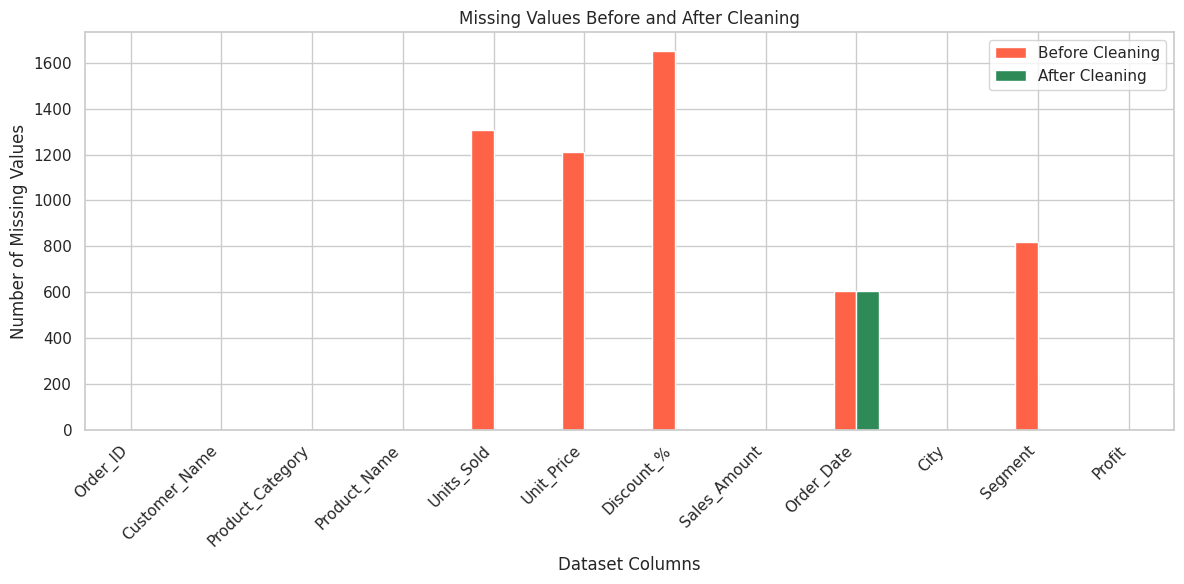

In [101]:
missing_comparison[
    ["Before Cleaning", "After Cleaning"]
].plot(
    kind="bar",
    figsize=(12, 6),
    color=["tomato", "seagreen"]
)

plt.title("Missing Values Before and After Cleaning")
plt.xlabel("Dataset Columns")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=45, ha="right")
plt.legend()
plt.tight_layout()
plt.show()

In [102]:
quality_summary = pd.DataFrame({
    "Metric": [
        "Total Rows",
        "Original Columns",
        "Missing Values",
        "Duplicate Rows"
    ],
    "Before Cleaning": [
        len(df_original),
        len(df_original.columns),
        df_original.isnull().sum().sum(),
        df_original.duplicated().sum()
    ],
    "After Cleaning": [
        len(df_clean),
        len(df_clean[original_columns].columns),
        df_clean[original_columns].isnull().sum().sum(),
        df_clean[original_columns].duplicated().sum()
    ]
})

display(quality_summary)

,Metric,Before Cleaning,After Cleaning
0,Total Rows,2500,2500
1,Original Columns,12,12
2,Missing Values,5594,606
3,Duplicate Rows,0,0


In [103]:
datatype_comparison = pd.DataFrame({
    "Before Cleaning": df_original.dtypes.astype(str),
    "After Cleaning": df_clean[original_columns].dtypes.astype(str)
})

print("Data Type Comparison:")
display(datatype_comparison)

Data Type Comparison:


,Before Cleaning,After Cleaning
Order_ID,int64,int64
Customer_Name,object,string
Product_Category,object,string
Product_Name,object,string
Units_Sold,float64,float64
Unit_Price,float64,float64
Discount_%,float64,float64
Sales_Amount,float64,float64
Order_Date,object,datetime64[ns]
City,object,string


### Data Quality Comparison – Observations

The original dataset contained 2,500 records and 12 columns, with 5,594 missing cells and no exact duplicate rows.

The preprocessing stage included standardising text formatting, identifying missing information, applying documented numerical imputation methods and converting order dates into datetime format.

The before-and-after comparison shows which missing values were handled and which remain unresolved.

Missing numerical values that were replaced using medians represent estimated values rather than verified original transaction information. Missing dates were not assigned fabricated dates.

Potential outliers were identified using the IQR method and retained for further investigation.

The final quality assessment is based on the comparison tables generated from the processed dataset.

In [104]:
# Export the processed dataset
output_file = "Snitch_Fashion_Sales_Cleaned.csv"

df_clean.to_csv(output_file, index=False)

print("Dataset exported successfully!")
print("Filename:", output_file)
print("Rows:", len(df_clean))
print("Columns:", len(df_clean.columns))

Dataset exported successfully!
Filename: Snitch_Fashion_Sales_Cleaned.csv
Rows: 2500
Columns: 20


In [105]:
from google.colab import files

files.download("Snitch_Fashion_Sales_Cleaned.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Project Results and Discussion

The Snitch Fashion Sales dataset originally contained 2,500 records and 12 columns. Initial data inspection identified 5,594 missing values across five attributes: Units_Sold, Unit_Price, Discount_%, Order_Date and Segment. No exact duplicate records were found.

### Data Cleaning Results

The preprocessing workflow retained all 2,500 records and expanded the dataset from 12 to 20 columns by adding indicators for missing, invalid and potentially unusual values.

Missing values in Units_Sold and Unit_Price were addressed through median imputation. Missing customer segments were labelled as Unknown. The Discount_% column was validated using a fractional range of 0 to 1, and 189 values exceeding this range were identified as invalid. Missing and invalid discount values were replaced using the median of valid observations.

Text formatting was standardised to improve consistency, and the Order_Date column was converted into datetime format to support time-based analysis.

The number of missing cells decreased from **5,594 to 606**, representing a reduction of approximately **89.2%**. All remaining missing values occur in the Order_Date column.

The corrected date conversion preserved the original 606 missing dates without introducing additional missing values. These dates were left unfilled because their actual values could not be reliably determined.

The Interquartile Range (IQR) method was used to flag potential outliers in Units_Sold, Unit_Price, Sales_Amount and Profit. These observations were retained rather than automatically removed because unusual transactions do not necessarily indicate data errors.

### Overall Findings

The preprocessing workflow substantially reduced missing information while preserving all 2,500 original records. The addition of eight indicator columns improved transparency by identifying imputed values, invalid discounts and potential outliers.

The cleaned dataset contains 20 columns, with no exact duplicate records and 606 remaining missing values. Numerical and categorical fields that previously contained missing information were processed, while unavailable order dates were preserved as missing.

Overall, the cleaning process improved the dataset's consistency and suitability for further retail sales analysis. However, the remaining missing dates may affect time-based analysis, and imputed numerical values should be interpreted as estimates rather than verified transaction information.

## Conclusion

This project focused on cleaning and preprocessing the Snitch Fashion Sales dataset using Python and Pandas. The original dataset contained 2,500 records and 12 columns, with 5,594 missing values across five attributes.

The preprocessing process reduced missing values from 5,594 to 606, achieving an improvement of approximately 89.2%. All 2,500 records were retained, and eight additional indicator columns were introduced to document missing, invalid and potentially unusual values.

Missing numerical values were addressed through median imputation, categorical information was standardised, and invalid discount values were identified and treated. Order dates were converted into datetime format, while the 606 originally missing dates were preserved. Potential outliers were identified using the IQR method without automatically removing unusual transactions.

The final dataset contains 2,500 records and 20 columns, with no exact duplicate records. The cleaning process improved data consistency and reduced incomplete information, making the dataset more suitable for further retail sales analysis. However, the remaining missing dates and estimated numerical values must be considered when interpreting analytical results.

## Limitations

1. **Missing Order Dates:** The cleaned dataset contains 606 missing values in the Order_Date column. These records may limit the accuracy and completeness of time-based sales analysis.

2. **Numerical Imputation:** Missing values in Units_Sold and Unit_Price were replaced using median values. Although this approach reduces missing information, the estimated values may differ from actual transaction values.

3. **Unknown Customer Segments:** Missing values in the Segment column were labelled Unknown because the original customer classifications could not be verified.

4. **Discount Validation:** A total of 189 observed discount values exceeded the assumed valid fractional range of 0 to 1. These values were treated as invalid and replaced using median imputation. This treatment depends on the assumption that discounts are represented as fractions.

5. **Outlier Detection:** The IQR method identified potentially unusual numerical observations. However, statistical outliers do not necessarily indicate incorrect transactions, so these records were retained.

6. **Limited Data Verification:** The dataset did not include supporting transaction records to independently verify missing or inconsistent values.

7. **Potential Analytical Bias:** Median imputation may influence the distribution of numerical variables and affect subsequent statistical analysis.

## Future Scope

Future improvements could include applying advanced imputation methods, validating missing transaction information against original business records and introducing automated data quality checks.

The cleaned dataset could also be used to analyse monthly sales trends, product category performance, profitability and customer segments. Further investigation of outliers and discount patterns could improve the reliability of future analysis.